In [1]:
import os
from pathlib import Path

ROOT = Path.cwd() if (Path.cwd() / "nn").exists() else Path.cwd().parent
os.chdir(ROOT)

In [2]:
%load_ext autoreload
%autoreload 2

import numpy as np
import matplotlib.pyplot as plt

from nn import *
from nn.data import make_moons, make_xor, save_csv, load_csv, train_test_split
from nn.visualizations import visualize_net, plot_history, plot_decision_boundary

# Training from scratch

Everything from the earlier steps, end to end:

1. load a dataset
2. build a network out of `multipleNeuron` layers
3. one training step by hand: forward, loss, backward, update
4. the training loop
5. watch it learn
6. save a checkpoint
7. load it back and keep training

## 1. Data

Two interleaving half-moons, 200 points, written to `data/moons.csv` the first time and read back from that file after.

In [3]:
data_path = Path("data/moons.csv")
if not data_path.exists():
    X, y = make_moons(n_samples=200, noise=0.15, seed=0)
    save_csv(data_path, X, y)

X, y = load_csv(data_path)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, seed=0)

print("all  ", X.shape, y.shape)
print("train", X_train.shape, " test", X_test.shape)
print(np.column_stack([X[:5], y[:5]]))

all   (200, 2) (200,)
train (160, 2)  test (40, 2)
[[-0.50497199  0.83796174  0.        ]
 [ 0.74976493  0.6501375   0.        ]
 [ 0.89971406 -0.11240547  0.        ]
 [ 1.10805471  0.17282067  0.        ]
 [-0.90426805  0.57805763  0.        ]]


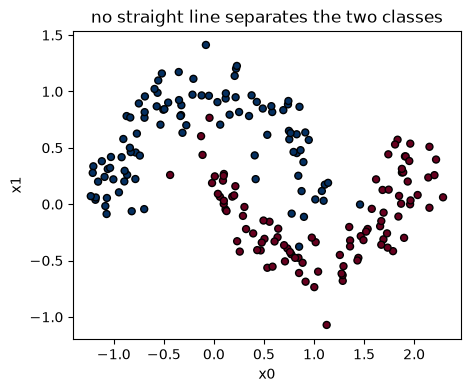

In [4]:
plt.figure(figsize=(5, 4))
plt.scatter(X[:, 0], X[:, 1], c=y, cmap="RdBu_r", edgecolors="k", s=25)
plt.title("no straight line separates the two classes")
plt.xlabel("x0")
plt.ylabel("x1")
plt.show()

## 2. Build the network

2 inputs, 8 tanh neurons, 1 sigmoid output. The output is the probability of class 1, so the loss is binary cross-entropy. Weights start random, so the seed makes this run repeatable.

In [5]:
np.random.seed(0)
net = stackLayers([
    multipleNeuron(n=8, n_inputs=2, activation=tanh),
    multipleNeuron(n=1, n_inputs=8, activation=sigmoid),
])
loss_fn = binary_cross_entropy
lr = 0.1
net

stackLayers(2 -> 8 tanh -> 1 sigmoid)

untrained  loss 0.4974  acc 0.762


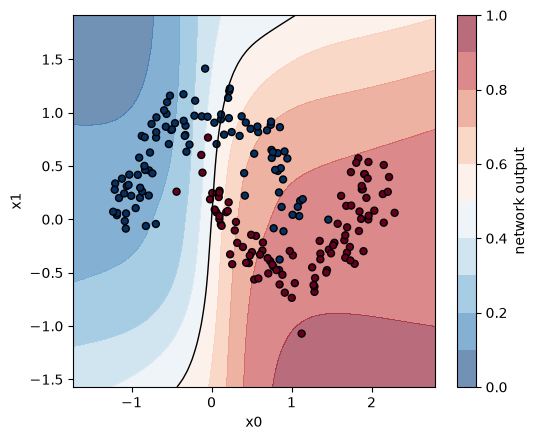

In [6]:
loss, acc = evaluate(net, X_train, y_train, loss_fn)
print(f"untrained  loss {loss:.4f}  acc {acc:.3f}")
plot_decision_boundary(net, X, y)

## 3. One step by hand

One sample through the whole cycle. Forward gives a prediction, the loss scores it, backward fills in `dW` and `db` on every neuron, and the update moves each weight a little against its gradient: `w = w - lr * dW`.

In [7]:
x0, t0 = X_train[0], np.array([y_train[0]])

pred = net.forward(x0)
loss_before = loss_fn(t0, pred)

net.backward(binary_cross_entropy_derivative(t0, pred))
first = net.layers[0].neurons[0]
print("layer 0 neuron 0   w ", np.round(first.w, 4), "  dW", np.round(first.dW, 4))

sgd_step(net, lr)
print("after the update   w ", np.round(first.w, 4))

loss_after = loss_fn(t0, net.forward(x0))
print(f"target {t0[0]:.0f}   pred {pred[0]:.4f}   loss on this sample {float(loss_before):.4f} -> {float(loss_after):.4f}")

layer 0 neuron 0   w  [1.7641 0.4002]   dW [-0.0021 -0.0006]
after the update   w  [1.7643 0.4002]
target 1   pred 0.8054   loss on this sample 0.2164 -> 0.1092


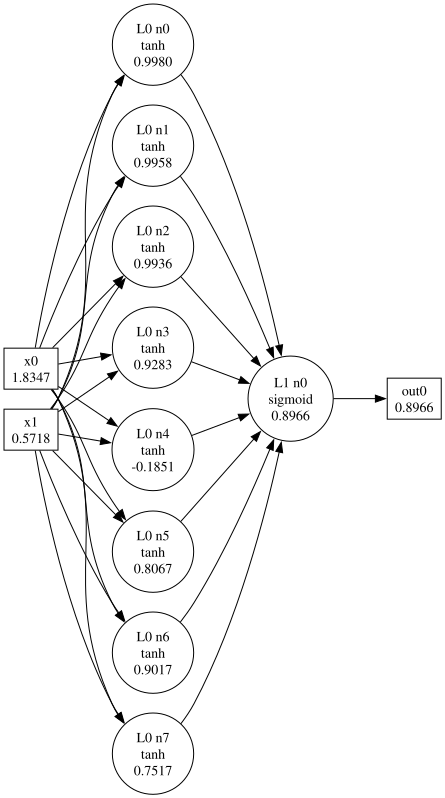

In [8]:
visualize_net(net)

## 4. The training loop

An epoch is that same step on every training sample once, in shuffled order. `train_step` is the four lines above in one call. Three epochs written out:

In [9]:
for epoch in range(1, 4):
    for i in np.random.permutation(len(X_train)):
        train_step(net, X_train[i], np.array([y_train[i]]), loss_fn, lr)
    loss, acc = evaluate(net, X_train, y_train, loss_fn)
    print(f"epoch {epoch}  loss {loss:.4f}  acc {acc:.3f}")

epoch 1  loss 0.3018  acc 0.869
epoch 2  loss 0.3036  acc 0.875
epoch 3  loss 0.2414  acc 0.900


`train` is that loop, plus a score on the held-out test set after every epoch and a `history` record for plotting.

In [10]:
history = train(net, X_train, y_train, loss_fn, lr=lr, epochs=100,
                X_val=X_test, Y_val=y_test, log_every=10)

epoch    1  loss 0.2746  acc 0.881  val_loss 0.5443  val_acc 0.675


epoch   10  loss 0.1159  acc 0.969  val_loss 0.1234  val_acc 0.975
epoch   20  loss 0.0732  acc 0.981  val_loss 0.0614  val_acc 0.975
epoch   30  loss 0.0667  acc 0.981  val_loss 0.1310  val_acc 0.950


epoch   40  loss 0.0529  acc 0.981  val_loss 0.0408  val_acc 1.000
epoch   50  loss 0.0550  acc 0.988  val_loss 0.0328  val_acc 1.000
epoch   60  loss 0.0434  acc 0.981  val_loss 0.0614  val_acc 0.950


epoch   70  loss 0.0396  acc 0.981  val_loss 0.0400  val_acc 1.000
epoch   80  loss 0.0353  acc 0.988  val_loss 0.0653  val_acc 0.975
epoch   90  loss 0.0435  acc 0.988  val_loss 0.0242  val_acc 1.000
epoch  100  loss 0.0344  acc 0.988  val_loss 0.0319  val_acc 1.000


## 5. Watch it learn

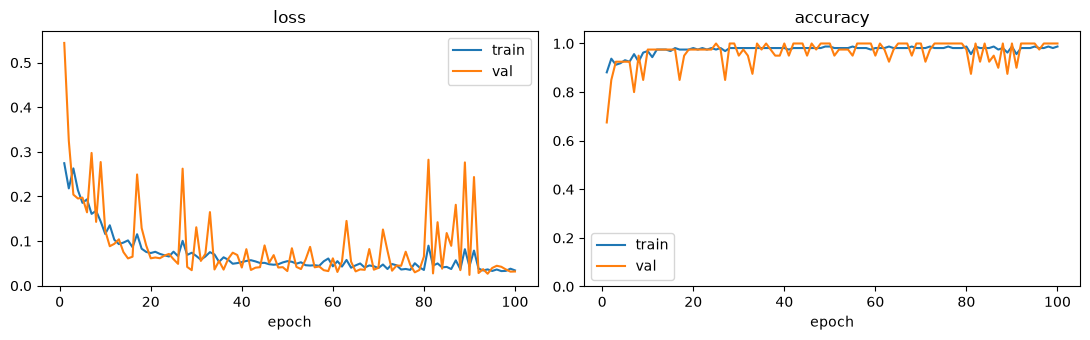

In [11]:
plot_history(history)

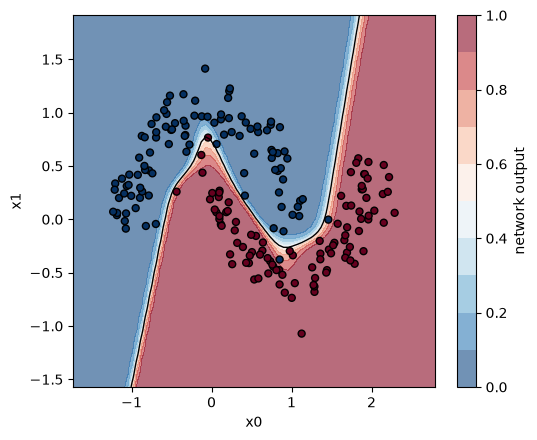

In [12]:
plot_decision_boundary(net, X, y)

## 6. Save a checkpoint

Every layer's weights and biases, the architecture, and anything passed as a keyword, saved to one `.npz` file.

In [13]:
ckpt_path = save_checkpoint(
    net, "checkpoints/moons_2-8-1",
    epoch=history["epoch"][-1], lr=lr,
    loss=history["loss"][-1], val_accuracy=history["val_accuracy"][-1],
    history=history,
)
ckpt_path

PosixPath('checkpoints/moons_2-8-1.npz')

## 7. Load it back and keep training

A fresh network rebuilt from the file should give exactly the same predictions. Passing the saved history to `train` continues the epoch count.

In [14]:
restored, meta = load_checkpoint(ckpt_path)
print(restored, "  saved at epoch", meta["epoch"], "  val_acc", meta["val_accuracy"])
print("same predictions:", np.allclose(predict(net, X_test), predict(restored, X_test)))

stackLayers(2 -> 8 tanh -> 1 sigmoid)   saved at epoch 100   val_acc 1.0
same predictions: True


epoch  101  loss 0.0340  acc 0.988  val_loss 0.0449  val_acc 0.975
epoch  105  loss 0.0310  acc 0.981  val_loss 0.0347  val_acc 1.000
epoch  110  loss 0.0303  acc 0.988  val_loss 0.0336  val_acc 1.000
epoch  115  loss 0.0336  acc 0.988  val_loss 0.0257  val_acc 1.000
epoch  120  loss 0.0297  acc 0.981  val_loss 0.0284  val_acc 1.000


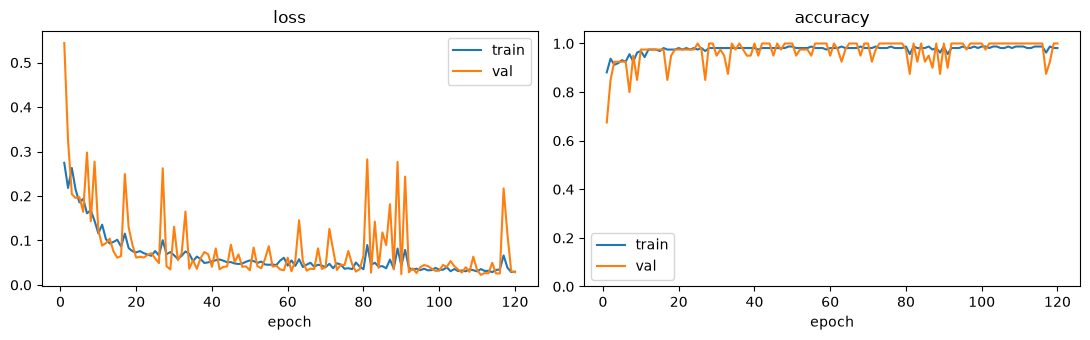

In [15]:
history = train(restored, X_train, y_train, loss_fn, lr=lr, epochs=20,
                X_val=X_test, Y_val=y_test, log_every=5, history=meta["history"])
plot_history(history)